## **Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import learning_curve

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error, r2_score

##**Load dataset**

In [ ]:
df = pd.read_csv("aqi5.csv")
df.head()

,City,PM2.5,PM10,NO2,SO2,CO,O3,AQI,AQI_Category
0,City_1,9.5,14.4,29.6,8.7,0.50,9.1,34.8,Good
1,City_2,1.0,19.7,24.6,1.0,0.24,8.5,34.2,Good
2,City_3,2.7,26.3,8.2,0.5,0.79,11.8,19.9,Good
3,City_4,34.3,60.8,5.5,14.7,0.20,4.2,42.5,Good
4,City_5,1.0,16.1,1.0,0.5,0.05,1.3,14.7,Good


##**Data pre processing**

In [ ]:
df.info()
df.shape

df.isnull().sum()

num_cols = df.select_dtypes(include=['float64','int64']).columns

for col in num_cols:
    df[col].fillna(df[col].mean(), inplace=True)

df = df.drop_duplicates()

if "City" in df.columns:
    df = df.drop(columns=["City"])

df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   City          1000 non-null   object 
 1   PM2.5         1000 non-null   float64
 2   PM10          1000 non-null   float64
 3   NO2           1000 non-null   float64
 4   SO2           1000 non-null   float64
 5   CO            1000 non-null   float64
 6   O3            1000 non-null   float64
 7   AQI           1000 non-null   float64
 8   AQI_Category  1000 non-null   object 
dtypes: float64(7), object(2)
memory usage: 70.4+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PM2.5         1000 non-null   float64
 1   PM10          1000 non-null   float64
 2   NO2           1000 non-null   float64
 3   SO2           1000 non-null   float64
 4   C

/tmp/ipykernel_173/1989794871.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


(1000, 8)

##**Select features and targets**

In [ ]:
X = df[["PM2.5","PM10","NO2","SO2","CO","O3"]]
y_reg = df["AQI"]
y_cls = df["AQI_Category"]

##**Train-test split**

In [ ]:
X_train, X_test, y_train_reg, y_test_reg, y_train_cls, y_test_cls = train_test_split(X, y_reg, y_cls, test_size=0.2, random_state=42)

##**Training regression model**

In [ ]:
reg_model = RandomForestRegressor(random_state=42)
reg_model.fit(X_train, y_train_reg)

RandomForestRegressor(random_state=42)

##**Regression results**

In [ ]:
y_pred_reg = reg_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 11.01661224242735
R2 Score: 0.9763662405298636


##**Comparison of actual vs predicted AQI values**

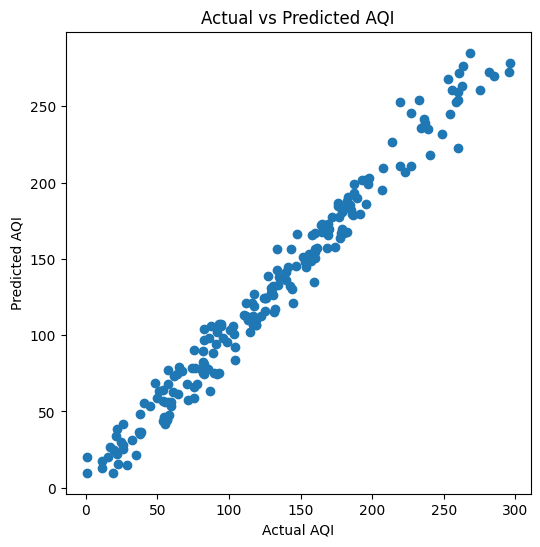

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_reg, y_pred_reg)
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")

plt.show()

##**Train classification model**

In [ ]:
clf_model = RandomForestClassifier(random_state=42)
clf_model.fit(X_train, y_train_cls)

RandomForestClassifier(random_state=42)

##**Training accuracy score**

In [ ]:
train_pred = clf_model.predict(X_train)
train_accuracy = accuracy_score(y_train_cls, train_pred)

print("Training Accuracy:", train_accuracy)

Training Accuracy: 1.0


##**Testing accuracy score**

In [ ]:
test_pred = clf_model.predict(X_test)
test_accuracy = accuracy_score(y_test_cls, test_pred)

print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.85


##**Testing accuracy graph**

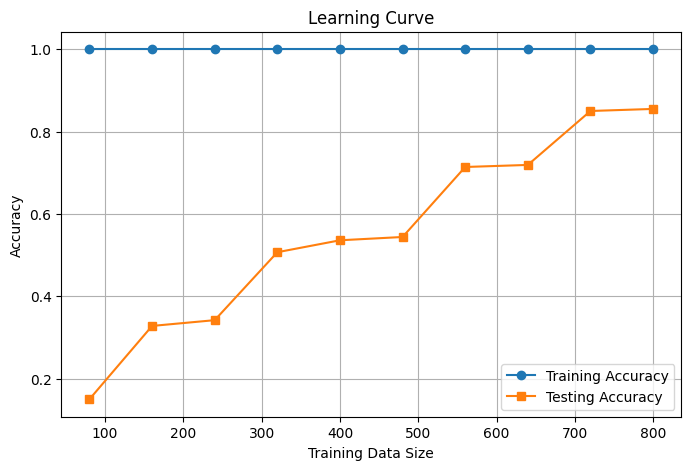

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(clf_model,X,y_cls,cv=5,scoring="accuracy",train_sizes=np.linspace(0.1, 1.0, 10),random_state=42)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8,5))
plt.plot(train_sizes, train_mean, marker='o', label="Training Accuracy")
plt.plot(train_sizes, test_mean, marker='s', label="Testing Accuracy")
plt.xlabel("Training Data Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)

plt.show()

##**Confusion matrix**

In [ ]:
cm = confusion_matrix(y_test_cls, test_pred)
print(cm)

[[22  5  0  0  0]
 [ 6 40  0  6  0]
 [ 0  0 40  5  1]
 [ 0  2  3 39  0]
 [ 0  0  2  0 29]]


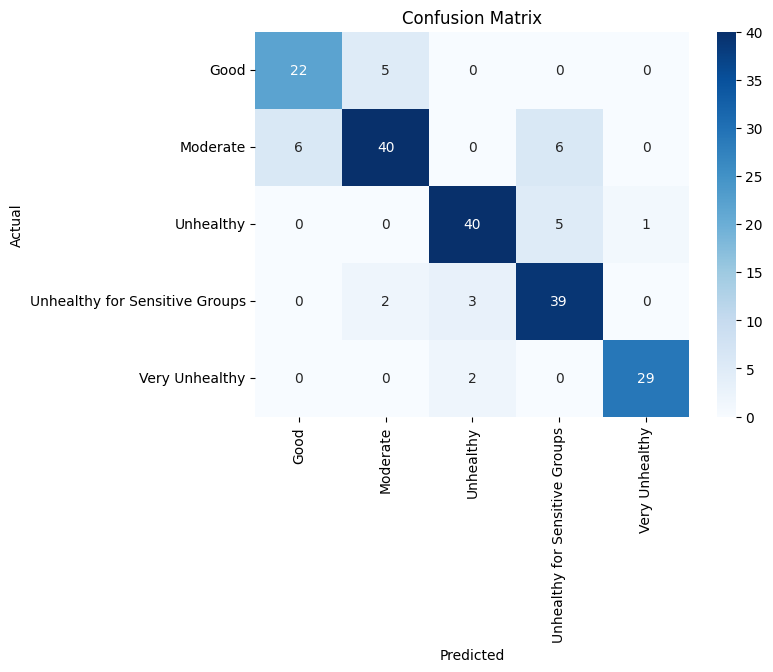

In [ ]:
cm = confusion_matrix(y_test_cls, test_pred)

plt.figure(figsize=(7,5))

sns.heatmap(cm, annot=True, cmap="Blues", fmt="d", xticklabels=clf_model.classes_, yticklabels=clf_model.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print("Training data: ",X_train.shape)
print("Testing data: ",X_test.shape)

Training data:  (800, 6)
Testing data:  (200, 6)


##**Classification scores**

In [ ]:
test_pred = clf_model.predict(X_test)

print("Classification Report:\n")
print(classification_report(y_test_cls, test_pred))

Classification Report:

                                precision    recall  f1-score   support

                          Good       0.79      0.81      0.80        27
                      Moderate       0.85      0.77      0.81        52
                     Unhealthy       0.89      0.87      0.88        46
Unhealthy for Sensitive Groups       0.78      0.89      0.83        44
                Very Unhealthy       0.97      0.94      0.95        31

                      accuracy                           0.85       200
                     macro avg       0.85      0.86      0.85       200
                  weighted avg       0.85      0.85      0.85       200



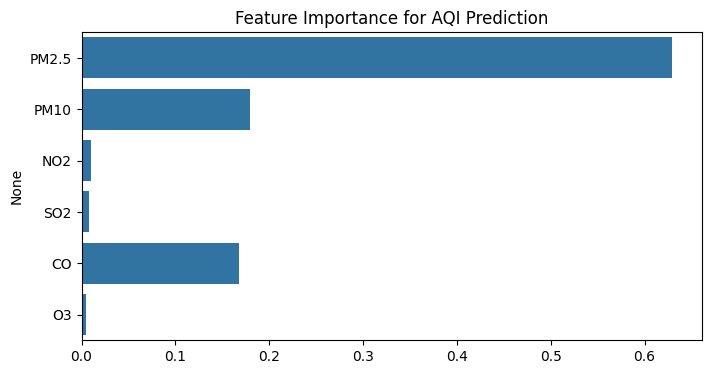

In [ ]:
importance = reg_model.feature_importances_
features = X.columns
plt.figure(figsize=(8,4))
sns.barplot(x=importance, y=features)
plt.title("Feature Importance for AQI Prediction")

plt.show()

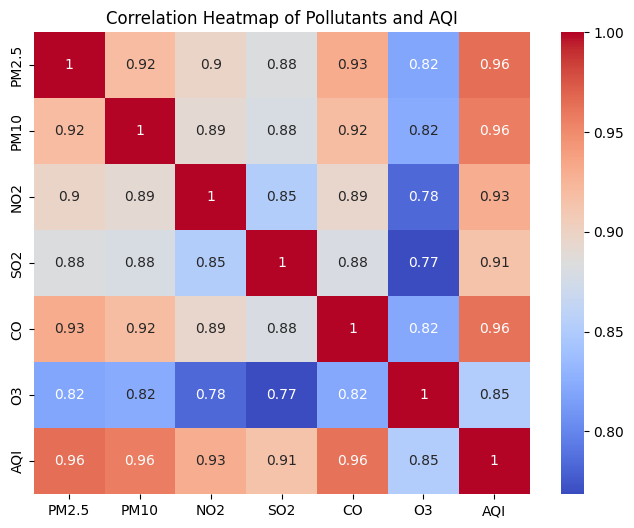

In [ ]:
plt.figure(figsize=(8,6))
correlation = df[["PM2.5","PM10","NO2","SO2","CO","O3","AQI"]].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Pollutants and AQI")

plt.show()

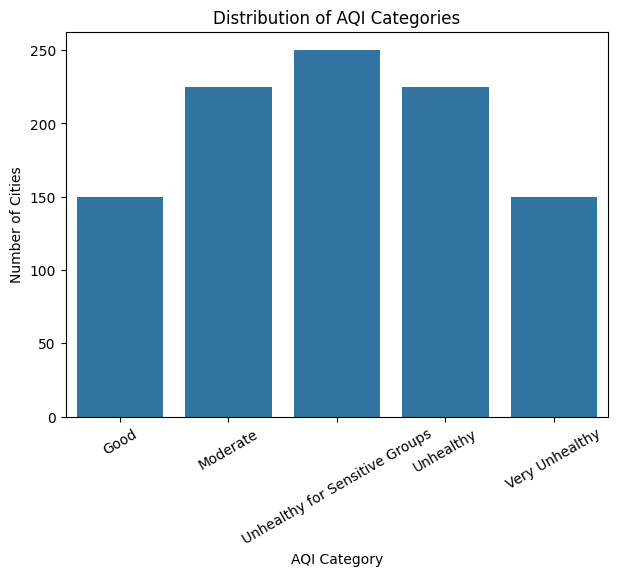

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(x="AQI_Category", data=df)
plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Cities")
plt.xticks(rotation=30)

plt.show()

In [ ]:
new_city = pd.DataFrame({"PM2.5":[40], "PM10":[100], "NO2":[40], "SO2":[12], "CO":[1.2], "O3":[35]})

predicted_aqi = reg_model.predict(new_city)
predicted_category = clf_model.predict(new_city)

print("Predicted AQI:", predicted_aqi[0])
print("Predicted AQI Category:", predicted_category[0])

Predicted AQI: 91.76100000000002
Predicted AQI Category: Unhealthy for Sensitive Groups
